# Clase práctica: AutoML con PyCaret

**Objetivo:** recorrer el ciclo completo de un proyecto de *machine learning* con muy poco código: preparar datos, comparar modelos, ajustarlos, evaluarlos, combinarlos y dejarlos listos para producción.

| Parte | Problema | Dataset | Idea clave |
|---|---|---|---|
| 1 | Clasificación | `diabetes` (Pima Indians) | El flujo completo, de `setup()` a `save_model()` |
| 2 | Regresión | `insurance` | La API orientada a objetos y la transformación del objetivo |
| 3 | Clustering | `jewellery` | Aprendizaje no supervisado con la misma lógica |
| 4 | Ejercicios | — | Practicar por tu cuenta |

> **Flujo PyCaret:** `setup` → `compare_models` → `create_model` → `tune_model` → `plot_model` → `predict_model` → `finalize_model` → `save_model`

## 0. Preparación del entorno

PyCaret 3.3.2 (última versión estable) funciona con **Python 3.9, 3.10 y 3.11**. Con Python 3.12 o superior la instalación falla, así que conviene crear un entorno dedicado:

```bash
# Opción A: conda
conda create -n pycaret python=3.11 -y && conda activate pycaret
pip install pycaret==3.3.2 jupyter

# Opción B: uv
uv venv -p 3.11 .venv && source .venv/bin/activate
uv pip install pycaret==3.3.2 jupyter
```

Si ya estás en un entorno con Python 3.11, basta con ejecutar la celda siguiente (quita el `#`).

In [81]:
# !pip install -q pycaret==3.3.2

In [82]:
import sys
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import pycaret
import sklearn

print("Python   :", sys.version.split()[0])
print("PyCaret  :", pycaret.__version__)
print("sklearn  :", sklearn.__version__)
pd.set_option("display.max_columns", 50)

Python   : 3.11.15
PyCaret  : 3.3.2
sklearn  : 1.4.2


---
# Parte 1 · Clasificación: ¿el paciente tiene diabetes?

Usaremos el dataset **Pima Indians Diabetes** (768 pacientes, 8 variables clínicas). La variable objetivo vale `1` si el paciente desarrolló diabetes y `0` si no.

### 1.1 Cargar los datos

In [140]:
from pycaret.datasets import get_data

df = get_data("diabetes", verbose=False)

# Los nombres originales son muy largos: los acortamos para trabajar cómodos
df.columns = ["embarazos", "glucosa", "presion", "pliegue_piel",
              "insulina", "imc", "pedigri", "edad", "diabetes"]
df.head()

,embarazos,glucosa,presion,pliegue_piel,insulina,imc,pedigri,edad,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 1.2 Exploración rápida

Antes de automatizar nada, **mira los datos**. AutoML no sustituye el sentido común.

In [84]:
print(df.shape)
df.describe().T.round(2)

(768, 9)


,count,mean,std,min,25%,50%,75%,max
embarazos,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
glucosa,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
presion,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
pliegue_piel,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
insulina,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
imc,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
pedigri,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
edad,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
diabetes,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


In [85]:
# ¿Está balanceada la variable objetivo?
df["diabetes"].value_counts(normalize=True).round(3)

diabetes
0    0.651
1    0.349
Name: proportion, dtype: float64

In [86]:
# Valores imposibles: nadie tiene glucosa, presión o IMC igual a 0.
# En este dataset, un 0 significa "dato no registrado".
cols_cero = ["glucosa", "presion", "pliegue_piel", "insulina", "imc"]
(df[cols_cero] == 0).sum()

glucosa           5
presion          35
pliegue_piel    227
insulina        374
imc              11
dtype: int64

In [87]:
# Los marcamos como faltantes (NaN) y dejamos que PyCaret los impute en setup()
df[cols_cero] = df[cols_cero].replace(0, np.nan)
df.isna().sum()

embarazos         0
glucosa           5
presion          35
pliegue_piel    227
insulina        374
imc              11
pedigri           0
edad              0
diabetes          0
dtype: int64

### 1.3 Reservar datos "nuevos"

Separamos un 5 % de filas que **PyCaret nunca verá** durante el experimento. Al final las usaremos para simular la llegada de pacientes nuevos en producción.

In [88]:
datos_nuevos = df.sample(frac=0.05, random_state=42)
df_modelo = df.drop(datos_nuevos.index).reset_index(drop=True)
datos_nuevos = datos_nuevos.reset_index(drop=True)

print("Para modelar :", df_modelo.shape)
print("Datos nuevos :", datos_nuevos.shape)

Para modelar : (730, 9)
Datos nuevos : (38, 9)


### 1.4 `setup()`: el corazón de PyCaret

`setup()` **siempre va primero**. Con una sola llamada:

- divide los datos en *train* y *test* (estratificado),
- infiere el tipo de cada columna,
- construye un *pipeline* de preprocesamiento (imputación, codificación, escalado…),
- configura la validación cruzada.

Parámetros que usaremos:

| Parámetro | Qué hace |
|---|---|
| `target` | Columna a predecir |
| `session_id` | Semilla: hace el experimento reproducible |
| `train_size` | Proporción de entrenamiento (el resto es *test*) |
| `numeric_imputation` | Cómo rellenar faltantes numéricos (`mean`, `median`, …) |
| `normalize` | Escala las variables (útil para modelos lineales, KNN, SVM) |
| `fold` | Número de *folds* de validación cruzada |

In [89]:
from pycaret.classification import *

s = setup(
    data=df_modelo,
    target="diabetes",
    session_id=123,
    train_size=0.8,
    numeric_imputation="median",
    normalize=True,
    fold=5,
)

,Description,Value
0,Session id,123
1,Target,diabetes
2,Target type,Binary
3,Original data shape,"(730, 9)"
4,Transformed data shape,"(730, 9)"
5,Transformed train set shape,"(584, 9)"
6,Transformed test set shape,"(146, 9)"
7,Numeric features,8
8,Rows with missing values,48.9%
9,Preprocess,True


`get_config()` permite inspeccionar todo lo que creó `setup()`: los conjuntos de datos, el *pipeline*, la configuración de CV…

In [90]:
X_train_t = get_config("X_train_transformed")
print(X_train_t.shape)
X_train_t.head()

(584, 8)


,embarazos,glucosa,presion,pliegue_piel,insulina,imc,pedigri,edad
187,2.050879,0.445118,-0.061363,0.056935,-0.196070,2.819195,0.305285,0.597833
718,-0.847750,0.214550,1.235871,1.114358,-0.368745,0.564933,1.701542,0.335194
333,-0.268024,-1.992314,0.749408,-0.178048,-0.196070,0.265317,-0.671220,1.123111
58,-1.137613,0.807439,0.749408,0.056935,-0.196070,1.135633,3.811959,0.948019
708,2.340742,-0.707722,0.911563,0.409409,-0.422706,-0.362453,0.042940,1.123111


In [91]:
# El pipeline de preprocesamiento es un objeto de scikit-learn
get_config("pipeline")

Pipeline(memory=FastMemory(location=/var/folders/y4/wh20svfj197816v0mh0mncwh0000gn/T/joblib),
         steps=[('numerical_imputer',
                 TransformerWrapper(exclude=None,
                                    include=['embarazos', 'glucosa', 'presion',
                                             'pliegue_piel', 'insulina', 'imc',
                                             'pedigri', 'edad'],
                                    transformer=SimpleImputer(add_indicator=False,
                                                              copy=True,
                                                              fill_value=None,
                                                              keep_empty_features=False,
                                                              missing_...
                ('categorical_imputer',
                 TransformerWrapper(exclude=None, include=[],
                                    transformer=SimpleImputer(add_indicator=False,
                                                              copy=True,
                                                              fill_value=None,
                                                              keep_empty_features=False,
                                                              missing_values=nan,
                                                              strategy='most_frequent'))),
                ('normalize',
                 TransformerWrapper(exclude=None, include=None,
                                    transformer=StandardScaler(copy=True,
                                                               with_mean=True,
                                                               with_std=True)))],
         verbose=False)

### 1.5 `compare_models()`: entrenar y comparar todo de una vez

Entrena **todos** los modelos disponibles con validación cruzada y los ordena por la métrica que elijamos. En problemas médicos como este, el **AUC** es más informativo que la *accuracy*.

Excluimos `ridge` y `svm` porque **no calculan probabilidades** (`predict_proba`): las necesitamos para el *blend* con voto suave (`method="soft"`), para ajustar el umbral de decisión y para el AUC sobre datos nuevos.

In [92]:
# ridge y svm no tienen predict_proba: los excluimos para poder combinar modelos con voto "soft"
top3 = compare_models(sort="AUC", n_select=3, exclude=["ridge", "svm"])

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.7619,0.8400,0.5865,0.6829,0.6302,0.4565,0.4599,0.0180
et,Extra Trees Classifier,0.7568,0.8318,0.5617,0.6839,0.6167,0.4410,0.4457,0.0220
lda,Linear Discriminant Analysis,0.7654,0.8295,0.5473,0.7123,0.6178,0.4532,0.4621,0.0060
lr,Logistic Regression,0.7705,0.8290,0.5621,0.7176,0.6292,0.4670,0.4750,0.3160
rf,Random Forest Classifier,0.7602,0.8272,0.5861,0.6805,0.6290,0.4535,0.4568,0.2320
lightgbm,Light Gradient Boosting Machine,0.7705,0.8192,0.6455,0.6753,0.6590,0.4865,0.4875,0.3660
nb,Naive Bayes,0.7484,0.8078,0.5920,0.6514,0.6190,0.4323,0.4342,0.1900
qda,Quadratic Discriminant Analysis,0.7380,0.8049,0.5326,0.6550,0.5859,0.3974,0.4031,0.0060
ada,Ada Boost Classifier,0.7517,0.8048,0.5718,0.6676,0.6143,0.4334,0.4372,0.0100
knn,K Neighbors Classifier,0.7449,0.7981,0.6013,0.6399,0.6197,0.4282,0.4289,0.2060


In [93]:
# pull() devuelve la última tabla de resultados como DataFrame
ranking = pull()
ranking.head()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.7619,0.8400,0.5865,0.6829,0.6302,0.4565,0.4599,0.018
et,Extra Trees Classifier,0.7568,0.8318,0.5617,0.6839,0.6167,0.4410,0.4457,0.022
lda,Linear Discriminant Analysis,0.7654,0.8295,0.5473,0.7123,0.6178,0.4532,0.4621,0.006
lr,Logistic Regression,0.7705,0.8290,0.5621,0.7176,0.6292,0.4670,0.4750,0.316
rf,Random Forest Classifier,0.7602,0.8272,0.5861,0.6805,0.6290,0.4535,0.4568,0.232


In [94]:
top3

[GradientBoostingClassifier(ccp_alpha=0.0, criterion='friedman_mse', init=None,
                            learning_rate=0.1, loss='log_loss', max_depth=3,
                            max_features=None, max_leaf_nodes=None,
                            min_impurity_decrease=0.0, min_samples_leaf=1,
                            min_samples_split=2, min_weight_fraction_leaf=0.0,
                            n_estimators=100, n_iter_no_change=None,
                            random_state=123, subsample=1.0, tol=0.0001,
                            validation_fraction=0.1, verbose=0,
                            warm_start=False),
 ExtraTreesClassifier(bootstrap=False, ccp_alpha=0.0, class_weight=None,
                      criterion='gini', max_depth=None, max_features='sqrt',
                      max_leaf_nodes=None, max_samples=None,
                      min_impurity_decrease=0.0, min_samples_leaf=1,
                      min_samples_split=2, min_weight_fraction_leaf=0.0,
               

### 1.6 `create_model()`: entrenar un modelo concreto

`models()` lista los identificadores disponibles. Con `create_model()` entrenamos uno con validación cruzada y vemos la métrica **en cada *fold***: esto nos dice si el modelo es estable.

In [95]:
models()[["Name", "Turbo"]].head(16)

,Name,Turbo
ID,,
lr,Logistic Regression,True
knn,K Neighbors Classifier,True
nb,Naive Bayes,True
dt,Decision Tree Classifier,True
svm,SVM - Linear Kernel,True
rbfsvm,SVM - Radial Kernel,False
gpc,Gaussian Process Classifier,False
mlp,MLP Classifier,False
ridge,Ridge Classifier,True


In [96]:
rf = create_model("rf")

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7265,0.7816,0.5122,0.6364,0.5676,0.3710,0.3756
1,0.7863,0.8651,0.6341,0.7222,0.6753,0.5171,0.5195
2,0.7521,0.7896,0.6341,0.6500,0.6420,0.4525,0.4526
3,0.8034,0.8839,0.6250,0.7576,0.6849,0.5440,0.5493
4,0.7328,0.8156,0.5250,0.6364,0.5753,0.3830,0.3868
Mean,0.7602,0.8272,0.5861,0.6805,0.6290,0.4535,0.4568
Std,0.0300,0.0407,0.0554,0.0500,0.0492,0.0693,0.0693


### 1.7 `tune_model()`: ajustar hiperparámetros

Hace una búsqueda aleatoria (*random search*) sobre una rejilla predefinida.

- `optimize`: métrica a maximizar.
- `n_iter`: cuántas combinaciones probar.
- `choose_better=True`: si el modelo ajustado es peor que el original, devuelve el original.

In [97]:
rf_tuned = tune_model(rf, optimize="AUC", n_iter=20, choose_better=True)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7436,0.7988,0.6829,0.6222,0.6512,0.4492,0.4504
1,0.7863,0.8456,0.7805,0.6667,0.7191,0.5484,0.5528
2,0.7436,0.7956,0.7317,0.6122,0.6667,0.4610,0.4658
3,0.7863,0.9091,0.9000,0.6316,0.7423,0.5692,0.5953
4,0.7672,0.8362,0.7750,0.6327,0.6966,0.5109,0.5179
Mean,0.7654,0.8371,0.7740,0.6331,0.6952,0.5077,0.5164
Std,0.0191,0.0411,0.0721,0.0183,0.0333,0.0470,0.0538


Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [98]:
# ¿Qué hiperparámetros cambió?
rf_tuned.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': 'balanced_subsample',
 'criterion': 'entropy',
 'max_depth': 4,
 'max_features': 'log2',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0002,
 'min_samples_leaf': 5,
 'min_samples_split': 9,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 130,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': 123,
 'verbose': 0,
 'warm_start': False}

### 1.8 `plot_model()`: entender el modelo

Algunos gráficos útiles: `auc`, `confusion_matrix`, `pr`, `feature`, `learning`, `threshold`, `calibration`, `class_report`.

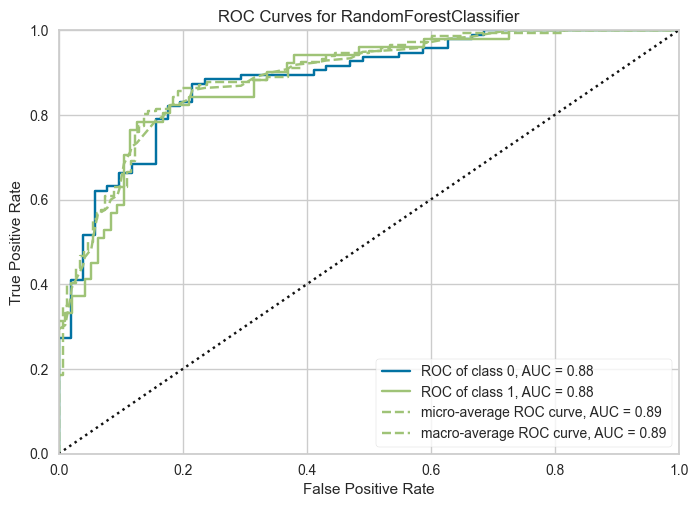

In [99]:
plot_model(rf_tuned, plot="auc")

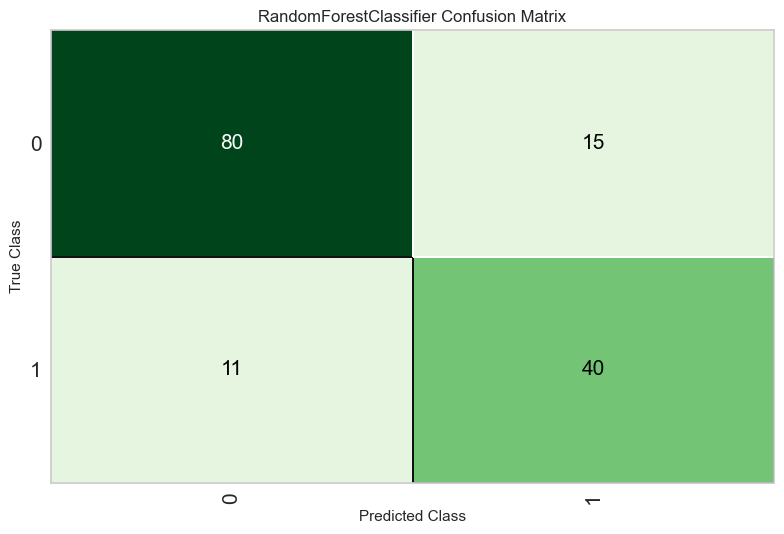

In [100]:
plot_model(rf_tuned, plot="confusion_matrix")

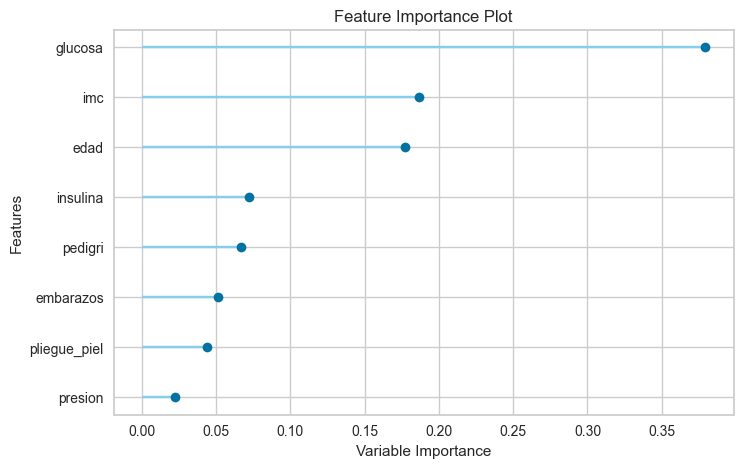

In [101]:
plot_model(rf_tuned, plot="feature")

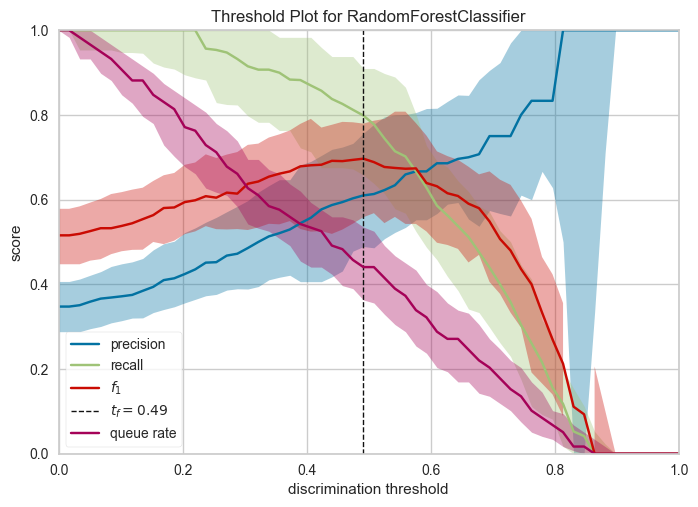

In [102]:
plot_model(rf_tuned, plot="threshold")

> **Tip:** en Jupyter, `evaluate_model(modelo)` abre un panel interactivo con todos los gráficos. Pruébalo descomentando la celda.

In [103]:
# evaluate_model(rf_tuned)

### 1.9 Combinar modelos

Tres estrategias de *ensemble*:

| Función | Idea |
|---|---|
| `ensemble_model(m, method="Bagging" / "Boosting")` | Muchas copias del mismo modelo |
| `blend_models([m1, m2, m3])` | Votación entre modelos distintos |
| `stack_models([m1, m2, m3])` | Un meta-modelo aprende a combinar las predicciones |

In [104]:
blend = blend_models(top3, optimize="AUC", method="soft")

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7265,0.7895,0.5122,0.6364,0.5676,0.3710,0.3756
1,0.7863,0.8697,0.5610,0.7667,0.6479,0.4997,0.5123
2,0.7436,0.8366,0.5366,0.6667,0.5946,0.4103,0.4155
3,0.8205,0.8932,0.6750,0.7714,0.7200,0.5888,0.5916
4,0.7672,0.8454,0.5750,0.6970,0.6301,0.4626,0.4672
Mean,0.7688,0.8469,0.5720,0.7076,0.6320,0.4665,0.4724
Std,0.0329,0.0348,0.0558,0.0537,0.0521,0.0753,0.0754


In [105]:
stack = stack_models(top3, optimize="AUC")

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7350,0.7908,0.5122,0.6562,0.5753,0.3870,0.3933
1,0.7778,0.8633,0.5366,0.7586,0.6286,0.4766,0.4911
2,0.7521,0.8363,0.5366,0.6875,0.6027,0.4266,0.4335
3,0.8291,0.8922,0.6750,0.7941,0.7297,0.6059,0.6102
4,0.7672,0.8438,0.5750,0.6970,0.6301,0.4626,0.4672
Mean,0.7723,0.8453,0.5671,0.7187,0.6333,0.4717,0.4791
Std,0.0318,0.0334,0.0576,0.0503,0.0522,0.0739,0.0734


### 1.10 `predict_model()`: evaluar en el conjunto de *test*

Hasta ahora todas las métricas eran de validación cruzada sobre *train*. Sin argumento `data`, `predict_model()` evalúa sobre el **20 % de test** que separó `setup()`. Si la métrica en test se parece a la de CV, el modelo **generaliza**.

In [106]:
candidatos = {"RF ajustado": rf_tuned, "Blend": blend, "Stack": stack}

resultados = []
for nombre, modelo in candidatos.items():
    predict_model(modelo, verbose=False)
    fila = pull().iloc[0]
    fila["Modelo"] = nombre
    resultados.append(fila)

tabla_test = pd.DataFrame(resultados).set_index("Modelo")[["Accuracy", "AUC", "Recall", "Prec.", "F1"]]
tabla_test

,Accuracy,AUC,Recall,Prec.,F1
Modelo,,,,,
RF ajustado,0.8219,0.8834,0.7843,0.7273,0.7547
Blend,0.7945,0.8621,0.5686,0.7838,0.6591
Stack,0.7877,0.8627,0.5490,0.7778,0.6437


> **¿Más complejo = mejor?** No necesariamente. Combinar modelos suele ayudar, pero no siempre gana a un buen modelo individual bien ajustado. Por eso **se mide, no se supone**.
>
> Compara esta tabla con la de validación cruzada: en CV el blend y el stack quedan ligeramente por delante, pero en *test* gana el RF ajustado. Las diferencias son menores que la variación entre *folds* (±0.04), así que en la práctica son empates.
>
> Aquí elegimos el de mejor AUC en *test*. Ojo: si comparas muchísimos candidatos sobre el mismo *test*, acabas sobreajustando también el *test*. Lo ideal es decidir con la validación cruzada y usar el *test* como confirmación final.

In [107]:
mejor_nombre = tabla_test["AUC"].idxmax()
modelo_elegido = candidatos[mejor_nombre]
print("Modelo elegido:", mejor_nombre)

Modelo elegido: RF ajustado


### 1.11 Ajustar el umbral de decisión

Por defecto se predice `1` si la probabilidad es ≥ 0.5. En un cribado médico quizá prefiramos **no dejar pasar casos positivos** (más *recall*), aunque aumenten los falsos positivos. Comparemos varios umbrales:

In [108]:
for umbral in [0.5, 0.4, 0.3]:
    predict_model(modelo_elegido, probability_threshold=umbral, verbose=False)
    m = pull().iloc[0]
    print(f"Umbral {umbral:.2f} -> Recall {m['Recall']:.3f} | Precisión {m['Prec.']:.3f} | F1 {m['F1']:.3f}")

Umbral 0.50 -> Recall 0.784 | Precisión 0.727 | F1 0.755
Umbral 0.40 -> Recall 0.843 | Precisión 0.651 | F1 0.735
Umbral 0.30 -> Recall 0.941 | Precisión 0.558 | F1 0.701


### 1.12 `finalize_model()` y predicción sobre datos nuevos

`finalize_model()` **reentrena el modelo con todos los datos** (train + test). Úsalo solo al final, cuando ya hayas elegido el modelo: después ya no hay test para evaluarlo.

In [109]:
modelo_final = finalize_model(modelo_elegido)
modelo_final

Pipeline(memory=Memory(location=None),
         steps=[('numerical_imputer',
                 TransformerWrapper(exclude=None,
                                    include=['embarazos', 'glucosa', 'presion',
                                             'pliegue_piel', 'insulina', 'imc',
                                             'pedigri', 'edad'],
                                    transformer=SimpleImputer(add_indicator=False,
                                                              copy=True,
                                                              fill_value=None,
                                                              keep_empty_features=False,
                                                              missing_values=nan,
                                                              strategy='median'))),
                ('categorical_imputer',...
                 RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                                        class_weight='balanced_subsample',
                                        criterion='entropy', max_depth=4,
                                        max_features='log2',
                                        max_leaf_nodes=None, max_samples=None,
                                        min_impurity_decrease=0.0002,
                                        min_samples_leaf=5, min_samples_split=9,
                                        min_weight_fraction_leaf=0.0,
                                        monotonic_cst=None, n_estimators=130,
                                        n_jobs=-1, oob_score=False,
                                        random_state=123, verbose=0,
                                        warm_start=False))],
         verbose=False)

In [110]:
# Los datos nuevos llegan sin la etiqueta: la quitamos para simular producción
X_nuevos = datos_nuevos.drop(columns="diabetes")

pred = predict_model(modelo_final, data=X_nuevos)
pred[["glucosa", "imc", "edad", "prediction_label", "prediction_score"]].head(10)

,glucosa,imc,edad,prediction_label,prediction_score
0,98.0,34.000000,43,1,0.5365
1,112.0,35.700001,21,0,0.6935
2,108.0,30.799999,21,0,0.7801
3,107.0,24.600000,34,0,0.6733
4,136.0,29.900000,50,1,0.6903
5,103.0,37.700001,55,1,0.5724
6,71.0,20.400000,22,0,0.9788
7,117.0,33.799999,44,1,0.6660
8,154.0,31.299999,37,1,0.7531
9,147.0,33.700001,65,1,0.6780


In [111]:
# Como en este ejercicio sí conocemos la verdad, podemos comprobar el acierto
from sklearn.metrics import accuracy_score, roc_auc_score

pred_prob = predict_model(modelo_final, data=X_nuevos, raw_score=True, verbose=False)
print("Accuracy:", round(accuracy_score(datos_nuevos["diabetes"], pred_prob["prediction_label"]), 3))
print("AUC     :", round(roc_auc_score(datos_nuevos["diabetes"], pred_prob["prediction_score_1"]), 3))

Accuracy: 0.658
AUC     : 0.789


> Con solo unas 38 filas, estas métricas son **muy ruidosas**: un par de aciertos o fallos las mueven varios puntos. No las compares a la ligera con las de *test* (146 filas) ni con las de CV.

### 1.13 Guardar y cargar el modelo

`save_model()` guarda **el pipeline completo** (preprocesamiento + modelo) en un `.pkl`. Quien lo cargue puede pasarle datos crudos, sin repetir la imputación ni el escalado.

In [112]:
save_model(modelo_final, "modelo_diabetes")

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['embarazos', 'glucosa', 'presion',
                                              'pliegue_piel', 'insulina', 'imc',
                                              'pedigri', 'edad'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty_features=False,
                                                               missing_values=nan,
                                                               strategy='median'))),
                 ('categorical_imputer',...
                  RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                              

In [113]:
modelo_cargado = load_model("modelo_diabetes")

paciente = pd.DataFrame([{
    "embarazos": 2, "glucosa": 165, "presion": 74, "pliegue_piel": np.nan,
    "insulina": np.nan, "imc": 36.1, "pedigri": 0.45, "edad": 41,
}])
predict_model(modelo_cargado, data=paciente)[["prediction_label", "prediction_score"]]

Transformation Pipeline and Model Successfully Loaded


,prediction_label,prediction_score
0,1,0.8189


---
# Parte 2 · Regresión: ¿cuánto costará el seguro médico?

Dataset **insurance**: 1 338 asegurados con edad, sexo, IMC, hijos, si fuma y región. Queremos predecir `charges` (coste anual).

Esta vez usaremos la **API orientada a objetos**: en lugar de funciones globales, creamos un objeto `RegressionExperiment` y llamamos a sus métodos. Los verbos son exactamente los mismos, pero:

- puedes tener **varios experimentos a la vez** sin que se pisen,
- el código es más explícito y fácil de llevar a scripts o producción.

In [114]:
from pycaret.datasets import get_data
from pycaret.regression import RegressionExperiment

seguros = get_data("insurance", verbose=False)
print(seguros.shape)
seguros.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [115]:
# La variable objetivo tiene una cola larga a la derecha
seguros["charges"].describe().round(0)

count     1338.0
mean     13270.0
std      12110.0
min       1122.0
25%       4740.0
50%       9382.0
75%      16640.0
max      63770.0
Name: charges, dtype: float64

In [116]:
seguros.groupby("smoker")["charges"].mean().round(0)

smoker
no      8434.0
yes    32050.0
Name: charges, dtype: float64

### 2.1 `setup()` con transformación del objetivo

`transform_target=True` transforma `charges` para que su distribución sea más simétrica. Las predicciones se devuelven automáticamente **en la escala original**.

- `transform_target_method="quantile"`: mapea el objetivo a una distribución normal usando sus cuantiles.
- El método por defecto (`"yeo-johnson"`) puede fallar con un `BracketError` de scipy cuando el objetivo toma valores tan grandes como estos (decenas de miles). Por eso usamos `quantile`.

Las variables categóricas (`sex`, `smoker`, `region`) se detectan y codifican solas.

In [117]:
exp_reg = RegressionExperiment()
exp_reg.setup(
    data=seguros,
    target="charges",
    session_id=123,
    normalize=True,
    transform_target=True,
    transform_target_method="quantile",
    fold=5,
)

,Description,Value
0,Session id,123
1,Target,charges
2,Target type,Regression
3,Original data shape,"(1338, 7)"
4,Transformed data shape,"(1338, 10)"
5,Transformed train set shape,"(936, 10)"
6,Transformed test set shape,"(402, 10)"
7,Numeric features,3
8,Categorical features,3
9,Preprocess,True


In [118]:
exp_reg.get_config("X_train_transformed").head()

,age,sex,bmi,children,smoker,region_northeast,region_southwest,region_southeast,region_northwest
300,-0.220584,0.995736,-0.521212,1.577352,-0.496325,1.788102,-0.551018,-0.615222,-0.58393
904,1.483407,-1.004283,0.757039,-0.879223,-0.496325,-0.559252,1.814822,-0.615222,-0.58393
670,-0.646582,0.995736,0.159393,1.577352,-0.496325,-0.559252,-0.551018,1.625430,-0.58393
617,0.702411,0.995736,-0.851356,0.758494,2.014810,-0.559252,1.814822,-0.615222,-0.58393
373,-0.930581,0.995736,0.384569,0.758494,2.014810,-0.559252,1.814822,-0.615222,-0.58393


### 2.2 Comparar, ajustar y evaluar
En regresión las métricas habituales son **MAE**, **RMSE** y **R²**. Ordenamos por MAE (error medio en dólares, fácil de explicar).

In [119]:
mejores_reg = exp_reg.compare_models(sort="MAE", n_select=3)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
rf,Random Forest Regressor,2367.1776,24068202.1604,4902.2420,0.8324,0.4178,0.2063,0.0260
gbr,Gradient Boosting Regressor,2398.0423,24757070.4516,4964.3441,0.8282,0.4108,0.1951,0.0180
et,Extra Trees Regressor,2505.1722,27222438.5309,5202.7927,0.8127,0.4422,0.2271,0.0220
lightgbm,Light Gradient Boosting Machine,2538.7665,24536336.6881,4950.6973,0.8286,0.4222,0.2160,0.6160
knn,K Neighbors Regressor,3271.2340,35023498.0000,5916.3226,0.7541,0.4581,0.2650,0.0120
dt,Decision Tree Regressor,3323.6097,47543462.1108,6874.6434,0.6675,0.5573,0.3893,0.0100
huber,Huber Regressor,3561.6897,58648717.9648,7628.2502,0.5976,0.4589,0.1829,0.0100
br,Bayesian Ridge,3680.6291,51253464.6556,7141.5138,0.6461,0.4449,0.2381,0.0100
ridge,Ridge Regression,3681.6934,51319440.6672,7146.0258,0.6456,0.4450,0.2377,0.0100
lar,Least Angle Regression,3682.2243,51355243.4056,7148.4788,0.6453,0.4451,0.2374,0.0080


In [120]:
mejor_reg = exp_reg.tune_model(mejores_reg[0], optimize="MAE", n_iter=20, choose_better=True)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,2658.8840,28681555.4518,5355.5164,0.8310,0.4099,0.2226
1,2193.1863,20100491.0002,4483.3571,0.7982,0.4257,0.2297
2,2521.6994,25081468.1328,5008.1402,0.8285,0.3939,0.1949
3,2256.4052,24455844.4088,4945.2851,0.8512,0.3829,0.1836
4,2392.3605,24157289.1235,4915.0065,0.8438,0.3882,0.2053
Mean,2404.5071,24495329.6234,4941.4610,0.8305,0.4001,0.2072
Std,170.3994,2731244.4791,278.0150,0.0182,0.0157,0.0171


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


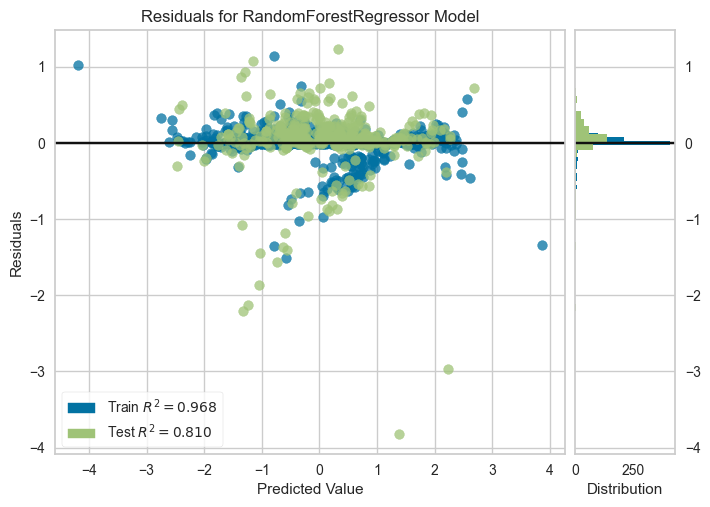

In [121]:
exp_reg.plot_model(mejor_reg, plot="residuals")

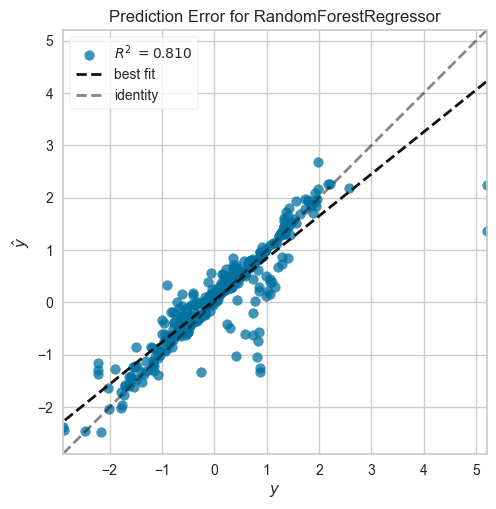

In [122]:
exp_reg.plot_model(mejor_reg, plot="error")

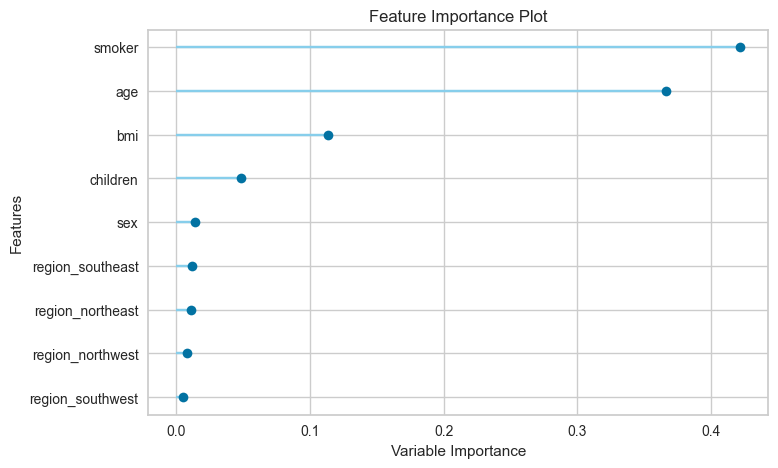

In [123]:
exp_reg.plot_model(mejor_reg, plot="feature")

### 2.3 Predicción sobre *test* y sobre un cliente nuevo

In [124]:
pred_test = exp_reg.predict_model(mejor_reg)
pred_test[["age", "bmi", "smoker", "charges", "prediction_label"]].head()

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Random Forest Regressor,2115.2320,17949413.6032,4236.6748,0.8744,0.3558,0.1902


,age,bmi,smoker,charges,prediction_label
650,49,42.680000,no,9800.888672,9745.609559
319,32,37.334999,no,4667.607422,7048.014529
314,27,31.400000,yes,34838.871094,37009.599553
150,35,24.129999,no,5125.215820,5385.255190
336,60,25.740000,no,12142.578125,17878.282951


In [125]:
final_reg = exp_reg.finalize_model(mejor_reg)

clientes = pd.DataFrame([
    {"age": 35, "sex": "female", "bmi": 24.0, "children": 1, "smoker": "no",  "region": "northwest"},
    {"age": 35, "sex": "female", "bmi": 24.0, "children": 1, "smoker": "yes", "region": "northwest"},
])
exp_reg.predict_model(final_reg, data=clientes)

,age,sex,bmi,children,smoker,region,prediction_label
0,35,female,24.0,1,no,northwest,5665.232111
1,35,female,24.0,1,yes,northwest,18898.418738


> Misma persona, solo cambia `smoker`: la diferencia en el coste predicho muestra lo que el modelo ha aprendido.

---
# Parte 3 · Clustering: segmentar clientes

Dataset **jewellery**: 505 clientes con `Age`, `Income`, `SpendingScore` y `Savings`. No hay variable objetivo: queremos descubrir **grupos** de clientes parecidos.

La lógica es la misma: `setup()` (sin `target`) → `create_model()` → `plot_model()` → `assign_model()`.

In [126]:
from pycaret.clustering import ClusteringExperiment

joyeria = get_data("jewellery", verbose=False)
joyeria.describe().round(2)

,Age,Income,SpendingScore,Savings
count,505.00,505.00,505.00,505.00
mean,59.02,75513.29,0.51,11862.46
std,24.14,35992.92,0.26,4949.23
min,17.00,12000.00,0.00,0.00
25%,34.00,34529.00,0.30,6828.71
50%,59.00,75078.00,0.37,14209.93
75%,85.00,107100.00,0.77,16047.27
max,97.00,142000.00,1.00,20000.00


In [127]:
exp_clu = ClusteringExperiment()
exp_clu.setup(data=joyeria, normalize=True, session_id=123)

,Description,Value
0,Session id,123
1,Original data shape,"(505, 4)"
2,Transformed data shape,"(505, 4)"
3,Numeric features,4
4,Preprocess,True
5,Imputation type,simple
6,Numeric imputation,mean
7,Categorical imputation,mode
8,Normalize,True
9,Normalize method,zscore


,Silhouette,Calinski-Harabasz,Davies-Bouldin,Homogeneity,Rand Index,Completeness
0,0.7325,1122.4249,0.3947,0,0,0


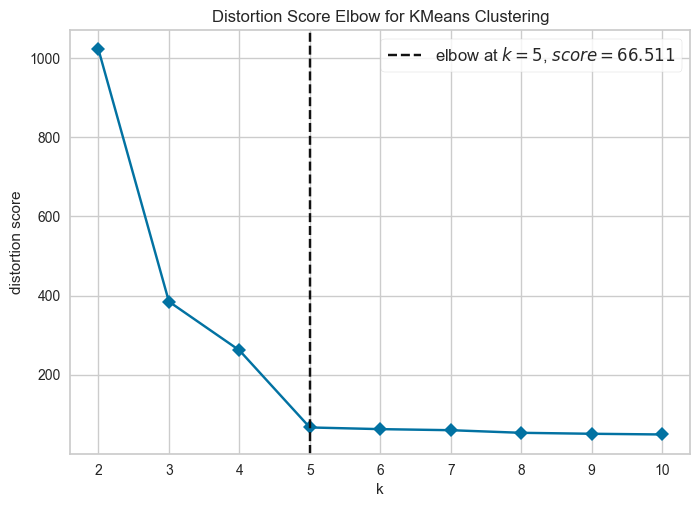

In [128]:
# Método del codo: ¿cuántos clusters tienen sentido?
kmeans_tmp = exp_clu.create_model("kmeans")
exp_clu.plot_model(kmeans_tmp, plot="elbow")

In [129]:
kmeans = exp_clu.create_model("kmeans", num_clusters=4)

,Silhouette,Calinski-Harabasz,Davies-Bouldin,Homogeneity,Rand Index,Completeness
0,0.7325,1122.4249,0.3947,0,0,0


In [130]:
exp_clu.plot_model(kmeans, plot="distribution")

In [131]:
# assign_model añade la etiqueta de cluster a cada cliente
segmentos = exp_clu.assign_model(kmeans)
resumen = segmentos.groupby("Cluster").mean(numeric_only=True).astype(float).round(2)
resumen["n_clientes"] = segmentos["Cluster"].value_counts()
resumen

,Age,Income,SpendingScore,Savings,n_clientes
Cluster,,,,,
Cluster 0,86.00,119944.04,0.07,14808.68,25
Cluster 1,51.31,85873.44,0.80,6213.05,207
Cluster 2,87.78,27866.10,0.33,16659.26,147
Cluster 3,32.78,105265.81,0.31,14962.78,126


> **Para discutir:** ¿qué nombre le pondrías a cada segmento? (p. ej. "jóvenes que gastan mucho", "ahorradores de mayor edad"…)

---
# Parte 4 · Ejercicios

Resuélvelos en las celdas vacías. Las pistas están al final de cada enunciado.

**Ejercicio 1 · Desbalanceo.** Repite el `setup()` de diabetes añadiendo `fix_imbalance=True` (aplica SMOTE). Compara el *Recall* del mejor modelo con el que obtuviste antes.
*Pista: crea un `ClassificationExperiment()` nuevo para no pisar el experimento de la Parte 1.*

In [132]:
from pycaret.classification import ClassificationExperiment

# Mismo setup que en la Parte 1 (misma semilla y train_size => mismo split de test) + SMOTE
exp_smote = ClassificationExperiment()
exp_smote.setup(
    data=df_modelo,
    target="diabetes",
    session_id=123,
    train_size=0.8,
    numeric_imputation="median",
    normalize=True,
    fold=5,
    fix_imbalance=True,
    verbose=False,
)
mejor_smote = exp_smote.compare_models(sort="AUC", exclude=["ridge", "svm"])

# Recall en test: modelo de la Parte 1 vs. mejor modelo con SMOTE
predict_model(modelo_elegido, verbose=False)
recall_antes = pull().iloc[0]["Recall"]
exp_smote.predict_model(mejor_smote, verbose=False)
recall_smote = exp_smote.pull().iloc[0]["Recall"]

print(f"Recall sin SMOTE ({mejor_nombre}): {recall_antes:.3f}")
print(f"Recall con SMOTE ({type(mejor_smote).__name__}): {recall_smote:.3f}")

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.7671,0.8361,0.7048,0.6527,0.6771,0.4955,0.4971,0.0220
lr,Logistic Regression,0.7535,0.8280,0.7100,0.6297,0.6668,0.4724,0.4752,0.0060
lda,Linear Discriminant Analysis,0.7552,0.8274,0.7000,0.6363,0.6659,0.4736,0.4755,0.0060
rf,Random Forest Classifier,0.7825,0.8253,0.6951,0.6856,0.6896,0.5224,0.5231,0.0320
et,Extra Trees Classifier,0.7569,0.8250,0.6656,0.6450,0.6547,0.4672,0.4678,0.0260
lightgbm,Light Gradient Boosting Machine,0.7688,0.8200,0.6948,0.6585,0.6758,0.4964,0.4971,0.4580
nb,Naive Bayes,0.7398,0.8137,0.6660,0.6139,0.6378,0.4354,0.4374,0.0060
qda,Quadratic Discriminant Analysis,0.7364,0.8038,0.6261,0.6204,0.6227,0.4202,0.4206,0.0040
ada,Ada Boost Classifier,0.7449,0.7991,0.6950,0.6184,0.6540,0.4531,0.4555,0.0160
knn,K Neighbors Classifier,0.7277,0.7866,0.7590,0.5842,0.6587,0.4387,0.4513,0.0120


Recall sin SMOTE (RF ajustado): 0.784
Recall con SMOTE (GradientBoostingClassifier): 0.726


**Ejercicio 2 · Comparar solo algunos modelos.** En el experimento de regresión, compara únicamente `lr`, `ridge`, `rf` y `lightgbm`.
*Pista: parámetro `include=[...]` de `compare_models()`.*

In [133]:
exp_reg.compare_models(include=["lr", "ridge", "rf", "lightgbm"], sort="MAE")

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
rf,Random Forest Regressor,2367.1776,24068202.1604,4902.2420,0.8324,0.4178,0.2063,0.0260
lightgbm,Light Gradient Boosting Machine,2538.7665,24536336.6881,4950.6973,0.8286,0.4222,0.2160,0.6340
ridge,Ridge Regression,3681.6934,51319440.6672,7146.0258,0.6456,0.4450,0.2377,0.0120
lr,Linear Regression,3707.1793,51779069.8803,7175.6630,0.6427,0.4466,0.2406,0.0080


RandomForestRegressor(bootstrap=True, ccp_alpha=0.0, criterion='squared_error',
                      max_depth=None, max_features=1.0, max_leaf_nodes=None,
                      max_samples=None, min_impurity_decrease=0.0,
                      min_samples_leaf=1, min_samples_split=2,
                      min_weight_fraction_leaf=0.0, monotonic_cst=None,
                      n_estimators=100, n_jobs=-1, oob_score=False,
                      random_state=123, verbose=0, warm_start=False)

**Ejercicio 3 · Métrica propia.** Añade al experimento de regresión una métrica "% de predicciones con error menor a 2 000 $" y vuelve a comparar.
*Pista: `exp_reg.add_metric(id, name, score_func, greater_is_better=True)`; `score_func` recibe `(y_true, y_pred, **kwargs)`.*

In [134]:
# **kwargs es obligatorio: PyCaret le pasa argumentos extra (p. ej. sample_weight).
# Sin él, la métrica falla en silencio y aparece como 0.0 en la tabla.
def pct_error_menor_2000(y_true, y_pred, **kwargs):
    """Proporción de predicciones cuyo error absoluto es menor a 2 000 $."""
    errores = np.abs(np.asarray(y_true) - np.asarray(y_pred))  # asarray evita que pandas alinee por índice
    return np.mean(errores < 2000)

exp_reg.add_metric(
    id="pct_err_2000",
    name="% err < 2000",
    score_func=pct_error_menor_2000,
    greater_is_better=True,
)

# La nueva métrica aparece como una columna más y podemos ordenar por ella
exp_reg.compare_models(sort="% err < 2000")

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,% err < 2000,TT (Sec)
huber,Huber Regressor,3561.6897,58648717.9648,7628.2502,0.5976,0.4589,0.1829,0.7649,0.0100
gbr,Gradient Boosting Regressor,2398.0423,24757070.4516,4964.3441,0.8282,0.4108,0.1951,0.7649,0.0200
dt,Decision Tree Regressor,3323.6097,47543462.1108,6874.6434,0.6675,0.5573,0.3893,0.7617,0.0100
et,Extra Trees Regressor,2505.1722,27222438.5309,5202.7927,0.8127,0.4422,0.2271,0.7490,0.0280
rf,Random Forest Regressor,2367.1776,24068202.1604,4902.2420,0.8324,0.4178,0.2063,0.7446,0.0280
lar,Least Angle Regression,3682.2243,51355243.4056,7148.4788,0.6453,0.4451,0.2374,0.7361,0.0080
ridge,Ridge Regression,3681.6934,51319440.6672,7146.0258,0.6456,0.4450,0.2377,0.7350,0.0100
br,Bayesian Ridge,3680.6291,51253464.6556,7141.5138,0.6461,0.4449,0.2381,0.7350,0.0080
lr,Linear Regression,3707.1793,51779069.8803,7175.6630,0.6427,0.4466,0.2406,0.7340,0.0100
lightgbm,Light Gradient Boosting Machine,2538.7665,24536336.6881,4950.6973,0.8286,0.4222,0.2160,0.6923,0.6300


HuberRegressor(alpha=0.0001, epsilon=1.35, fit_intercept=True, max_iter=100,
               tol=1e-05, warm_start=False)

**Ejercicio 4 · Ingeniería de variables.** En diabetes, prueba `setup(..., remove_multicollinearity=True, feature_selection=True, n_features_to_select=5)`. ¿Empeora mucho el AUC usando solo 5 variables? ¿Cuáles se quedan?
*Pista: `get_config("X_train_transformed").columns`.*

In [135]:
exp_fs = ClassificationExperiment()
exp_fs.setup(
    data=df_modelo,
    target="diabetes",
    session_id=123,
    train_size=0.8,
    numeric_imputation="median",
    normalize=True,
    fold=5,
    remove_multicollinearity=True,
    feature_selection=True,
    n_features_to_select=5,
    verbose=False,
)
print("Variables que se quedan:", list(exp_fs.get_config("X_train_transformed").columns))

mejor_fs = exp_fs.compare_models(sort="AUC", exclude=["ridge", "svm"])
auc_fs = exp_fs.pull().iloc[0]["AUC"]
print(f"AUC CV con 8 variables: {ranking['AUC'].iloc[0]:.4f}")
print(f"AUC CV con 5 variables: {auc_fs:.4f}")

Variables que se quedan: ['glucosa', 'presion', 'imc', 'pedigri', 'edad']


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.7602,0.8263,0.5870,0.6795,0.6279,0.4531,0.4571,0.3560
lr,Logistic Regression,0.7688,0.8251,0.5720,0.7078,0.6322,0.4666,0.4725,0.3580
lda,Linear Discriminant Analysis,0.7637,0.8249,0.5673,0.6976,0.6245,0.4552,0.4611,0.3540
rf,Random Forest Classifier,0.7602,0.8187,0.6063,0.6740,0.6366,0.4588,0.4615,0.3820
et,Extra Trees Classifier,0.7534,0.8181,0.5917,0.6667,0.6257,0.4430,0.4457,0.3800
nb,Naive Bayes,0.7535,0.8124,0.5868,0.6648,0.6225,0.4409,0.4433,0.3460
lightgbm,Light Gradient Boosting Machine,0.7637,0.8109,0.6356,0.6693,0.6517,0.4731,0.4737,0.6960
ada,Ada Boost Classifier,0.7499,0.8088,0.5671,0.6700,0.6109,0.4292,0.4347,0.3560
qda,Quadratic Discriminant Analysis,0.7243,0.7953,0.5177,0.6261,0.5657,0.3668,0.3710,0.3540
knn,K Neighbors Classifier,0.7294,0.7723,0.5670,0.6223,0.5929,0.3911,0.3923,0.3580


AUC CV con 8 variables: 0.8400
AUC CV con 5 variables: 0.8263


**Ejercicio 5 · Reto.** Elige otro dataset con `get_data("index")` (por ejemplo `credit`, `bank` o `employee`), identifica el tipo de problema y recorre el flujo completo hasta `save_model()`.

(24000, 24)
default
0    0.779
1    0.221
Name: proportion, dtype: float64


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
gbc,Gradient Boosting Classifier,0.8215,0.7827,0.3780,0.6710,0.4834,0.3856,0.4089,0.6500
lightgbm,Light Gradient Boosting Machine,0.8196,0.7779,0.3767,0.6620,0.4798,0.3806,0.4029,0.6600
ada,Ada Boost Classifier,0.8175,0.7739,0.3309,0.6789,0.4447,0.3508,0.3833,0.1460
rf,Random Forest Classifier,0.8127,0.7603,0.3667,0.6325,0.4638,0.3600,0.3799,0.1960
et,Extra Trees Classifier,0.8104,0.7487,0.3740,0.6185,0.4658,0.3590,0.3759,0.0840
nb,Naive Bayes,0.7438,0.7413,0.6241,0.4463,0.5193,0.3519,0.3616,0.0080
lr,Logistic Regression,0.8121,0.7271,0.2544,0.7085,0.3742,0.2916,0.3449,0.0100
qda,Quadratic Discriminant Analysis,0.4861,0.7229,0.8322,0.2799,0.4181,0.1303,0.1938,0.0100
lda,Linear Discriminant Analysis,0.8129,0.7224,0.2717,0.6972,0.3907,0.3047,0.3522,0.0100
knn,K Neighbors Classifier,0.7942,0.7038,0.3533,0.5546,0.4314,0.3133,0.3253,0.0580


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7792,0.7797,0.0000,0.0000,0.0000,0.0000,0.0000
1,0.7789,0.7883,0.0000,0.0000,0.0000,0.0000,0.0000
2,0.7789,0.7770,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.7789,0.7811,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.7789,0.7864,0.0000,0.0000,0.0000,0.0000,0.0000
Mean,0.7789,0.7825,0.0000,0.0000,0.0000,0.0000,0.0000
Std,0.0001,0.0042,0.0000,0.0000,0.0000,0.0000,0.0000


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


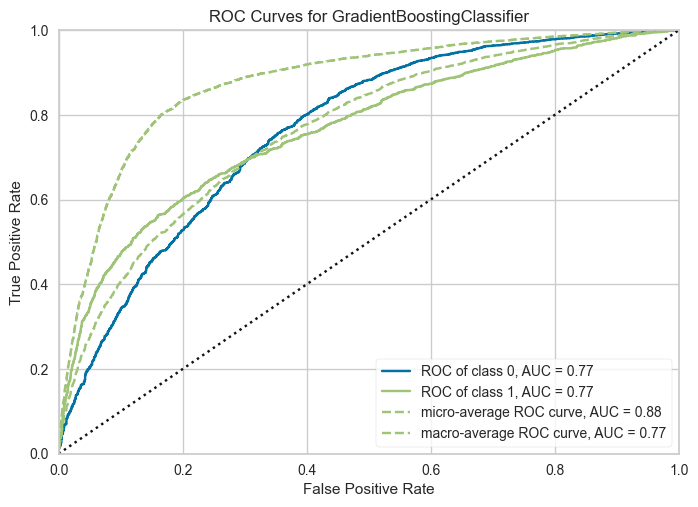

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Gradient Boosting Classifier,0.8158,0.7651,0.3386,0.6638,0.4484,0.3516,0.3803


Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['LIMIT_BAL', 'SEX', 'EDUCATION',
                                              'MARRIAGE', 'AGE', 'PAY_1',
                                              'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5',
                                              'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
                                              'BILL_AMT3', 'BILL_AMT4',
                                              'BILL_AMT5', 'BILL_AMT6',
                                              'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
                                              'PAY_AMT4', 'PAY_AMT5',
                                              'PAY_AMT6'],
                                     transform...
                                             criterion='friedman_mse', init=None,
                                             learning_rate=0.1, los

In [136]:
# Dataset "credit": ¿el cliente dejará de pagar su tarjeta? (default = 1) -> clasificación binaria
credito = get_data("credit", verbose=False)
print(credito.shape)
print(credito["default"].value_counts(normalize=True).round(3))

exp_cred = ClassificationExperiment()
exp_cred.setup(data=credito, target="default", session_id=123, normalize=True, fold=5, verbose=False)

mejor_cred = exp_cred.compare_models(sort="AUC", exclude=["ridge", "svm"])
mejor_cred = exp_cred.tune_model(mejor_cred, optimize="AUC", n_iter=10, choose_better=True)
exp_cred.plot_model(mejor_cred, plot="auc")
exp_cred.predict_model(mejor_cred)  # métricas en test

final_cred = exp_cred.finalize_model(mejor_cred)
exp_cred.save_model(final_cred, "modelo_credit")

---
# Resumen: chuleta de PyCaret

| Paso | Función | Para qué |
|---|---|---|
| 1 | `setup(data, target, session_id)` | Preprocesar y configurar el experimento |
| 2 | `compare_models(sort, n_select)` | Ranking de todos los modelos |
| 3 | `create_model("id")` | Entrenar un modelo concreto con CV |
| 4 | `tune_model(m, optimize, n_iter)` | Ajustar hiperparámetros |
| 5 | `blend_models` / `stack_models` / `ensemble_model` | Combinar modelos |
| 6 | `plot_model(m, plot)` / `evaluate_model(m)` | Diagnosticar |
| 7 | `predict_model(m, data)` | Evaluar en test o predecir |
| 8 | `finalize_model(m)` | Reentrenar con todos los datos |
| 9 | `save_model` / `load_model` | Persistir el pipeline completo |
| — | `pull()` / `get_config()` / `models()` | Recuperar tablas, objetos y catálogo |

**Buenas prácticas**

1. Mira los datos antes de automatizar (los ceros "imposibles" de diabetes).
2. Fija siempre `session_id` para poder reproducir resultados.
3. Elige la métrica según el problema, no por costumbre.
4. Compara CV con test: si difieren mucho, hay sobreajuste.
5. `finalize_model()` solo al final.

**Documentación:** https://pycaret.gitbook.io/docs